# 04 · Métrica de negocio y KPIs — DataByte / RescateAlimento
**Capstone · punto 6 "Métrica de negocio": *métrica justificada según las distribuciones de las features. Incorporar KPI es un plus.***

## Cómo respondemos a la consigna
| La consigna pide | Dónde lo resolvemos |
|---|---|
| Una métrica **justificada con las distribuciones de las features** | §1 mira las distribuciones (sesgo, ceros, dispersión) → §2 convierte cada hallazgo en una decisión de métrica → §3 define la métrica elegida y la compara con las alternativas. |
| **KPIs** (plus) | §5 define 8 KPIs con fórmula, fuente en el bot, meta y semáforo; §6 los calcula con una función reutilizable con datos reales. |

> ⚠️ Los datos siguen siendo **simulados** (ver notebook 01). Las *decisiones de métrica* se justifican con la forma de los datos, que es lo que el simulador replica a propósito;
> los **valores** de los KPIs son de ejemplo hasta tener ventas reales. Las **metas** son una **propuesta** para validar con el comercio y el docente.

## 0. Configuración y datos

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
rng = np.random.default_rng(42)

datos = pd.read_csv("data/dataset_modelado.csv", parse_dates=["fecha"], dtype={"telegram_id": str, "ean": str})
lotes = pd.read_csv("data/lotes_simulados.csv", parse_dates=["fecha_ingreso", "fecha_vencimiento"], dtype={"telegram_id": str, "ean": str})
params = json.load(open("data/parametros.json"))
cat = datos.groupby("ean").categoria.first()
lotes["categoria"] = lotes.ean.map(cat)
cerrados = lotes[lotes.cerrado].copy()                     # solo lotes terminados: se sabe cuánto se vendió y cuánto sobró
cerrados["merma_pct"] = cerrados.merma / cerrados.cantidad_inicial
print(f"Fuente: {params['fuente']} · {len(datos):,} filas diarias · {len(cerrados)} lotes cerrados")

Fuente: SIMULADO · 3,312 filas diarias · 364 lotes cerrados


## 1. Distribuciones de las features
Para elegir una métrica hay que saber **cómo se comportan los datos**: ¿simétricos o con cola larga? ¿hay muchos ceros? ¿la variabilidad es grande?
Resumimos con medidas que responden eso: **sesgo** (cola), **% de ceros**, **coeficiente de variación** (variabilidad relativa) y la **razón varianza/media** (¿se parece a un conteo Poisson?).

,media,mediana,desvío,sesgo,% ceros,CV (desvío/media),varianza/media,p95
feature,,,,,,,,
Ventas diarias (un.),9.17,8.00,6.82,1.63,0.91,0.74,5.07,23.00
Stock al inicio del día (un.),89.73,65.00,82.58,1.83,0.00,0.92,76.00,250.90
Días al vencimiento,17.61,10.00,20.09,1.81,3.93,1.14,22.91,70.00
Precio propio / precio competencia,0.95,0.97,0.09,-1.41,0.00,0.09,0.01,1.05


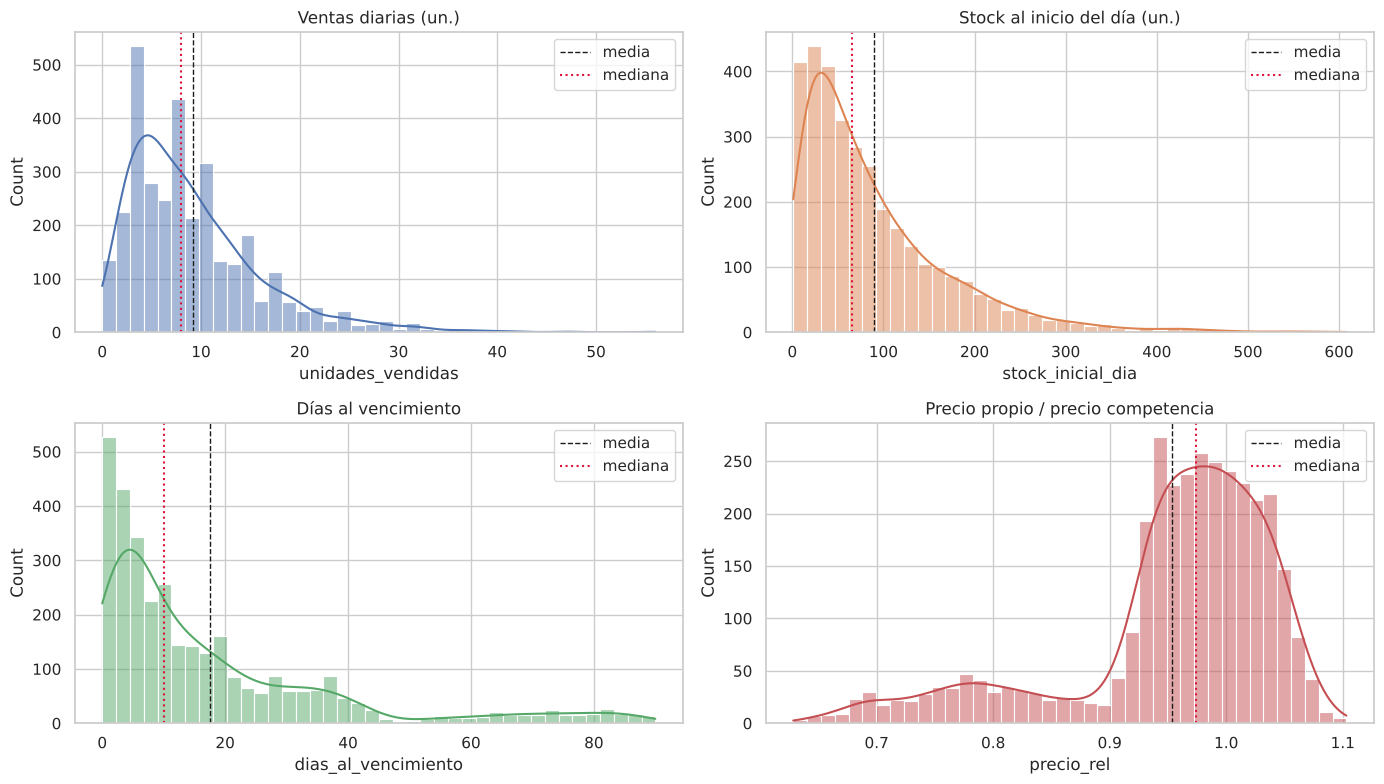

In [2]:
FEATURES = {"unidades_vendidas": "Ventas diarias (un.)", "stock_inicial_dia": "Stock al inicio del día (un.)",
            "dias_al_vencimiento": "Días al vencimiento", "precio_rel": "Precio propio / precio competencia"}
filas = []
for c, nombre in FEATURES.items():
    s = datos[c]
    filas.append({"feature": nombre, "media": s.mean(), "mediana": s.median(), "desvío": s.std(),
                  "sesgo": stats.skew(s), "% ceros": 100 * (s == 0).mean(), "CV (desvío/media)": s.std() / s.mean(),
                  "varianza/media": s.var() / s.mean(), "p95": s.quantile(.95)})
resumen = pd.DataFrame(filas).set_index("feature")
display(resumen.round(2))

fig, ax = plt.subplots(2, 2, figsize=(14, 8))
for a, (c, nombre) in zip(ax.ravel(), FEATURES.items()):
    sns.histplot(datos[c], bins=40, kde=True, ax=a, color=sns.color_palette("deep")[list(FEATURES).index(c)])
    a.axvline(datos[c].mean(), color="k", ls="--", lw=1, label="media"); a.axvline(datos[c].median(), color="crimson", ls=":", lw=1.5, label="mediana")
    a.set_title(nombre); a.legend()
plt.tight_layout(); plt.show()

### 1.1 La variable que más importa al negocio: la **merma por lote**
Es lo que el proyecto quiere reducir: de cada lote que entra, ¿qué parte vence sin venderse?

Lotes cerrados: 364
  Lotes SIN merma (0 %):           68 %
  Media simple de los % por lote:   7.0 %
  Mediana:                          0.0 %
  Percentil 90:                     26.9 %
  Máximo:                           61.8 %
  Sesgo:                            2.10


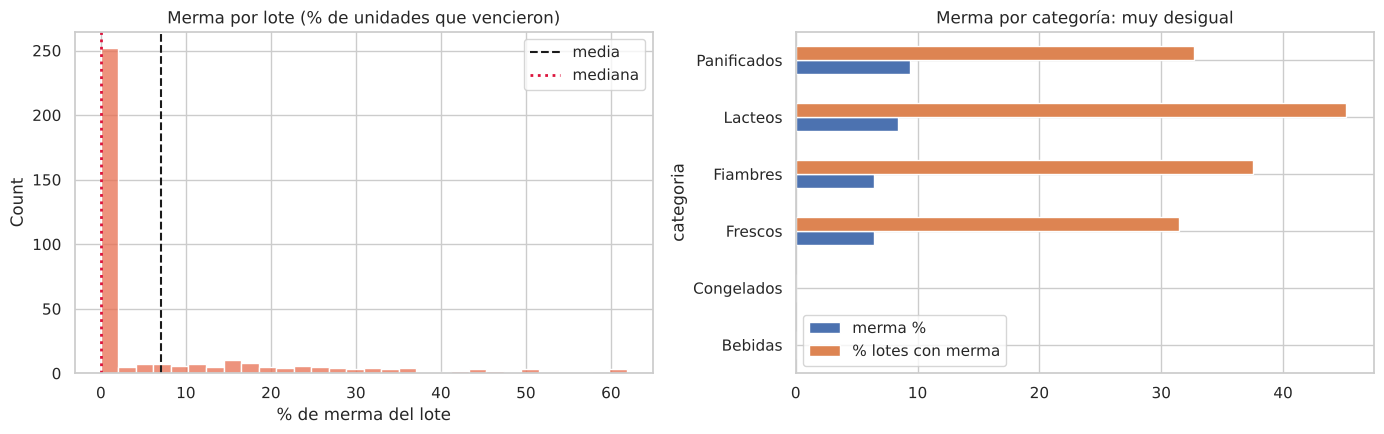

In [3]:
m = cerrados.merma_pct
print(f"Lotes cerrados: {len(m)}")
print(f"  Lotes SIN merma (0 %):           {100*(m==0).mean():.0f} %")
print(f"  Media simple de los % por lote:   {100*m.mean():.1f} %")
print(f"  Mediana:                          {100*m.median():.1f} %")
print(f"  Percentil 90:                     {100*m.quantile(.9):.1f} %")
print(f"  Máximo:                           {100*m.max():.1f} %")
print(f"  Sesgo:                            {stats.skew(m):.2f}")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(100 * m, bins=30, ax=ax[0], color="#e76f51"); ax[0].set_title("Merma por lote (% de unidades que vencieron)"); ax[0].set_xlabel("% de merma del lote")
ax[0].axvline(100 * m.mean(), color="k", ls="--", label="media"); ax[0].axvline(100 * m.median(), color="crimson", ls=":", lw=2, label="mediana"); ax[0].legend()
por_cat = cerrados.groupby("categoria").apply(lambda g: pd.Series({"merma %": 100 * g.merma.sum() / g.cantidad_inicial.sum(), "% lotes con merma": 100 * (g.merma > 0).mean()}))
por_cat.sort_values("merma %").plot.barh(ax=ax[1]); ax[1].set_title("Merma por categoría: muy desigual")
plt.tight_layout(); plt.show()

## 2. De la distribución a la decisión: qué métrica elegir y por qué
| Hallazgo en la distribución | Consecuencia para la métrica |
|---|---|
| **Ventas diarias**: asimétricas a la derecha (sesgo > 1), media > mediana, poca presencia de ceros pero **sin ser cero-libres** | La media se mueve por pocos días altos. Para medir el error de pronóstico conviene **MAE / WAPE** (robustas) y evitar **MAPE** (divide por la venta real: explota o no existe cuando es 0). |
| **Ventas**: varianza mayor que la media (sobredispersión) y CV alto | Hay mucho ruido natural: una métrica debe expresarse **en unidades de negocio** (unidades/día) para que el comerciante entienda si el error es grande o chico. |
| **Stock y días al vencimiento**: colas largas (sesgo > 1.5) y escalas muy distintas | No se pueden comparar lotes en valores absolutos: la métrica debe ser **relativa (%)** y **ponderada por tamaño**, si no, un lote chico pesa igual que uno enorme. |
| **Precio relativo**: angosto y centrado cerca de 1 (CV chico) | La competitividad de precio se resume bien con la **mediana** del índice; no hace falta una métrica compleja. |
| **Merma por lote**: **la mayoría de los lotes tiene 0 %** y unos pocos tienen mucha (distribución inflada de ceros, cola larga) | La **media simple de porcentajes por lote engaña** (los lotes chicos con merma total inflan o desinflan el resultado) y la mediana da 0 y no dice nada. → Usar la **merma ponderada (Σ sobrante ÷ Σ ingresado)**, **valorizada a costo** para que sea plata, y acompañarla de **intervalo de confianza** y del **% de lotes con merma**. |

In [4]:
# Comparación de formas de calcular "la merma" sobre los MISMOS lotes.
costo_ing = (cerrados.cantidad_inicial * cerrados.costo)
costo_merma = (cerrados.merma * cerrados.costo)
comparacion = pd.DataFrame({
    "valor": [100 * cerrados.merma_pct.mean(), 100 * cerrados.merma_pct.median(),
              100 * cerrados.merma.sum() / cerrados.cantidad_inicial.sum(), 100 * costo_merma.sum() / costo_ing.sum()],
    "problema / virtud": ["Cada lote pesa igual (uno de 5 un. = uno de 500). Sensible a lotes chicos.",
                          "Es 0: la mayoría de los lotes no tiene merma → no distingue nada.",
                          "Pondera por tamaño. Mezcla productos baratos y caros.",
                          "✔ Pondera por tamaño Y por costo: es la plata inmovilizada que se tira."]},
    index=["Media simple de % por lote", "Mediana de % por lote", "Merma ponderada (unidades)", "Merma valorizada a costo ✔"])
comparacion["valor"] = comparacion.valor.round(2).astype(str) + " %"
display(comparacion)

,valor,problema / virtud
Media simple de % por lote,7.04 %,Cada lote pesa igual (uno de 5 un. = uno de 50...
Mediana de % por lote,0.0 %,Es 0: la mayoría de los lotes no tiene merma →...
Merma ponderada (unidades),6.11 %,Pondera por tamaño. Mezcla productos baratos y...
Merma valorizada a costo ✔,5.28 %,✔ Pondera por tamaño Y por costo: es la plata ...


## 3. La métrica de negocio elegida
### 🎯 Métrica principal: **Merma valorizada (% del costo ingresado)**
$$\text{Merma valorizada} = \frac{\sum_{lotes\ cerrados} \text{unidades sin vender al vencer} \times \text{costo unitario}}{\sum_{lotes\ cerrados} \text{unidades ingresadas} \times \text{costo unitario}}$$
* **Por qué es la correcta**: (a) está en **plata**, el idioma del comerciante; (b) es **relativa y ponderada**, como exigen las colas largas de stock/vencimiento; (c) es lo que el producto promete reducir; (d) se mide **ya** con las pestañas `Lotes_Registrados` + `Ventas_Registradas`.
* **Cómo se informa**: siempre con **intervalo de confianza** (por la distribución inflada de ceros) y el **% de lotes con merma**.

### 🛡️ Métrica de control (guardarraíl): **Ganancia bruta por lote**
Una métrica sola se puede "hackear": bajar la merma regalando la mercadería (el defecto del Score v02.7 que vimos en el notebook 03). Por eso se mide siempre **junto** con la ganancia por lote:
si la merma baja pero la ganancia cae, la mejora **no es real**.

Merma valorizada = 5.3 %   (IC 95 %: 4.2 % – 6.5 %)


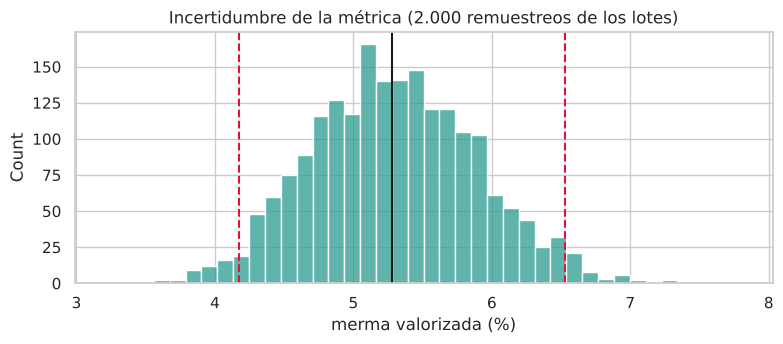

In [5]:
# Intervalo de confianza por bootstrap: con distribución inflada de ceros, la fórmula "normal" no es confiable.
def merma_valorizada(df):
    return df.eval("merma * costo").sum() / df.eval("cantidad_inicial * costo").sum()

estimado = merma_valorizada(cerrados)
boot = np.array([merma_valorizada(cerrados.sample(len(cerrados), replace=True, random_state=int(i))) for i in range(2000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Merma valorizada = {100*estimado:.1f} %   (IC 95 %: {100*lo:.1f} % – {100*hi:.1f} %)")

fig, ax = plt.subplots(figsize=(8, 3.6))
sns.histplot(100 * boot, bins=40, ax=ax, color="#2a9d8f"); ax.axvline(100 * estimado, color="k"); ax.axvline(100 * lo, color="crimson", ls="--"); ax.axvline(100 * hi, color="crimson", ls="--")
ax.set_title("Incertidumbre de la métrica (2.000 remuestreos de los lotes)"); ax.set_xlabel("merma valorizada (%)")
plt.tight_layout(); plt.show()

### 3.1 ¿Qué explica la merma? (indicador *adelantado*)
La merma es un indicador **atrasado**: se conoce cuando el lote ya venció. Para actuar a tiempo buscamos una variable **adelantada**. La hipótesis: la merma aparece cuando se **ingresa más de lo que se espera vender**.
Medimos el **ratio de sobrestock** = `unidades ingresadas ÷ (ventas esperadas por día × días de vida del lote)`.

,lotes,merma %,% lotes con merma
tramo,,,
<0.7,44.0,0.0,0.0
0.7-0.9,84.0,0.4,6.0
0.9-1.1,84.0,3.5,28.6
1.1-1.3,69.0,9.9,43.5
1.3-1.6,49.0,14.4,55.1
>1.6,34.0,29.5,85.3


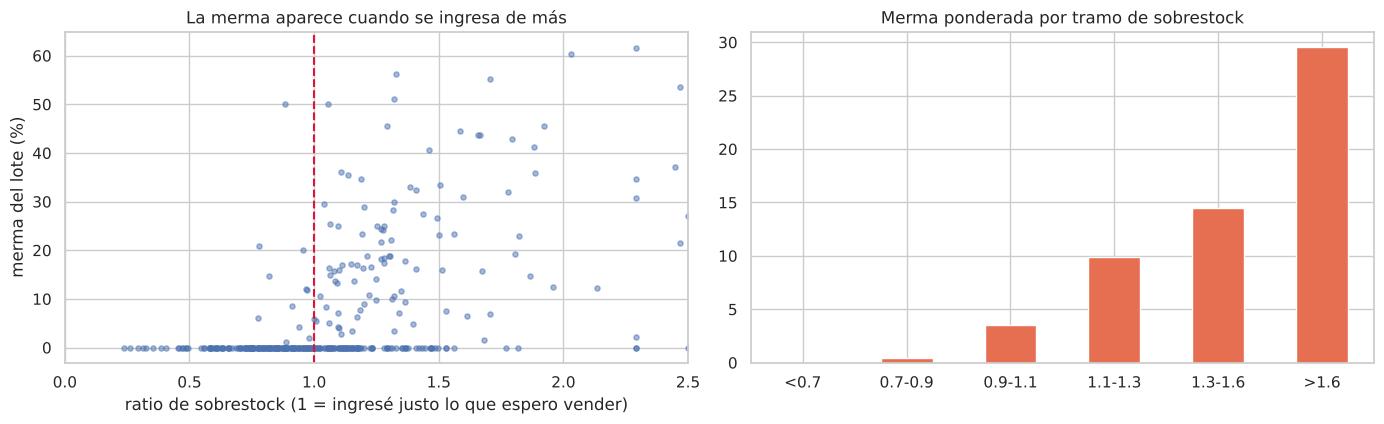

Correlación de Spearman sobrestock ↔ merma del lote: 0.57


In [6]:
venta_dia = datos.groupby(["telegram_id", "ean"]).unidades_vendidas.mean().rename("venta_dia")
c = cerrados.merge(venta_dia, left_on=["telegram_id", "ean"], right_index=True)
c["dias_vida"] = (c.fecha_vencimiento - c.fecha_ingreso).dt.days
c["sobrestock"] = c.cantidad_inicial / (c.venta_dia * c.dias_vida)
c["tramo"] = pd.cut(c.sobrestock, [0, .7, .9, 1.1, 1.3, 1.6, 10], labels=["<0.7", "0.7-0.9", "0.9-1.1", "1.1-1.3", "1.3-1.6", ">1.6"])
t = c.groupby("tramo", observed=True).apply(lambda g: pd.Series({"lotes": len(g), "merma %": 100 * g.merma.sum() / g.cantidad_inicial.sum(),
                                                                  "% lotes con merma": 100 * (g.merma > 0).mean()}))
display(t.round(1))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
ax[0].scatter(c.sobrestock, 100 * c.merma_pct, alpha=.5, s=14); ax[0].axvline(1.0, color="crimson", ls="--"); ax[0].set_xlim(0, 2.5)
ax[0].set_xlabel("ratio de sobrestock (1 = ingresé justo lo que espero vender)"); ax[0].set_ylabel("merma del lote (%)"); ax[0].set_title("La merma aparece cuando se ingresa de más")
t["merma %"].plot.bar(ax=ax[1], rot=0, color="#e76f51"); ax[1].set_title("Merma ponderada por tramo de sobrestock"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()
rho = stats.spearmanr(c.sobrestock, c.merma_pct)[0]
print(f"Correlación de Spearman sobrestock ↔ merma del lote: {rho:.2f}")

**Lectura:** hay un umbral claro cerca de `ratio ≈ 1`. Por encima, los lotes empiezan a perder mercadería; por debajo, casi no hay merma.
Esto da el **KPI adelantado** (*lotes con sobrestock > 1,1*): se puede mostrar **al cargar el lote** (antes de que venza) y es la base para una recomendación de "cuánto reponer" en una versión futura.

## 4. KPIs (plus de la consigna)
Un KPI es una métrica con **fórmula, fuente de datos, frecuencia, meta y responsable**. Armamos 8, de los cuales 3 son del negocio del comerciante, 3 del modelo/decisión y 2 de impacto.

| # | KPI | Fórmula | Fuente en el bot | Tipo |
|---|---|---|---|---|
| 1 | **Merma valorizada %** ⭐ *(métrica principal)* | Σ sobrante × costo ÷ Σ ingresado × costo | `Lotes_Registrados` (cantidad restante al vencer) | atrasado |
| 2 | **Ganancia bruta por lote** 🛡️ *(guardarraíl)* | ingresos del lote − costo × unidades ingresadas | `Ventas_Registradas` + costo del lote | atrasado |
| 3 | **Sell-through %** | unidades vendidas ÷ unidades ingresadas | `Ventas_Registradas` | atrasado |
| 4 | **% de lotes con merma** | lotes con sobrante > 0 ÷ lotes cerrados | `Lotes_Registrados` | atrasado |
| 5 | **Lotes en riesgo hoy** | lotes con nivel ROJO/NARANJA del Score ÷ lotes abiertos | `Score_Rescate` | adelantado |
| 6 | **Valor en riesgo hoy** | Σ precio × cantidad de lotes ROJO/NARANJA | `Score_Rescate` | adelantado |
| 7 | **Índice de precio vs competencia** | mediana de precio propio ÷ precio competencia | catálogo n8n | contexto |
| 8 | **Unidades rescatadas** | unidades vendidas con acción del Score que se habrían perdido | `Ventas_Registradas` + `Score_Rescate` | impacto social |

### 4.1 Función reutilizable: `calcular_kpis`
Recibe las dos tablas **tal como salen del Google Sheet** (exportadas a CSV o leídas con `gspread`) y devuelve los KPIs. Así el mismo código sirve con datos simulados hoy y con datos reales mañana.

In [7]:
def calcular_kpis(lotes_cerrados, ventas, score=None, precio_rel=None):
    # lotes_cerrados: id_lote, cantidad_inicial, costo, merma (unidades sin vender al vencer)
    # ventas: id_lote, unidades_vendidas, precio_venta (una fila por venta/día)
    # score (opcional): columnas nivel, valor_en_riesgo ; precio_rel (opcional): serie de precio propio/competencia
    v = ventas.assign(ing=ventas.unidades_vendidas * ventas.precio_venta).groupby("id_lote").agg(
        ing_total=("ing", "sum"), und_vendidas=("unidades_vendidas", "sum"))
    l = lotes_cerrados[["id_lote", "cantidad_inicial", "costo", "merma"]].merge(v, left_on="id_lote", right_index=True, how="left").fillna(0)
    costo_lote = l.cantidad_inicial * l.costo
    k = {
        "Merma valorizada %": 100 * (l.merma * l.costo).sum() / costo_lote.sum(),
        "Ganancia bruta por lote ($)": (l.ing_total - costo_lote).mean(),
        "Sell-through %": 100 * l.und_vendidas.sum() / l.cantidad_inicial.sum(),
        "% de lotes con merma": 100 * (l.merma > 0).mean(),
    }
    if score is not None and len(score):
        riesgo = score.nivel.isin(["ROJO", "NARANJA"])
        k["Lotes en riesgo hoy %"] = 100 * riesgo.mean()
        k["Valor en riesgo hoy ($)"] = score.loc[riesgo, "valor_en_riesgo"].sum()
    if precio_rel is not None and len(precio_rel):
        k["Índice de precio vs competencia"] = float(np.median(precio_rel))
    return k

# OJO: se usan TODAS las ventas (ventas_limpias), no dataset_modelado: este último descarta las primeras 4 semanas
# de cada serie (no tienen historia para los lags) y dejaría lotes sin sus ventas iniciales.
ventas_lotes = pd.read_csv("data/ventas_limpias.csv")[["id_lote", "unidades_vendidas", "precio_venta"]]
# Chequeo de coherencia: sell-through + merma (unidades) debe dar ~100 % en los lotes cerrados.
_v = ventas_lotes.groupby("id_lote").unidades_vendidas.sum()
_chk = cerrados.set_index("id_lote").cantidad_inicial.sub(_v.reindex(cerrados.id_lote).values).sub(cerrados.set_index("id_lote").merma)
_desc = _chk.abs().sum() / cerrados.cantidad_inicial.sum()
print(f"Chequeo vendidas + merma = ingresadas: {(_chk.abs() > 1e-6).sum()} lotes con diferencia, que suman {100*_desc:.2f} % de las unidades ingresadas.")
print("→ Esperable: el notebook 01 imputó/topeó algunas ventas sucias (nulos, negativos, tipeo ×20); en datos reales también habría que tolerarlo.")
assert _desc < 0.02, "El descuadre es demasiado grande: revisar la limpieza"
score = pd.read_csv("data/score_simulado.csv", dtype={"telegram_id": str})
kpi = calcular_kpis(cerrados, ventas_lotes, score, datos.precio_rel)
pd.Series(kpi).round(2).to_frame("valor")

Chequeo vendidas + merma = ingresadas: 31 lotes con diferencia, que suman 0.40 % de las unidades ingresadas.
→ Esperable: el notebook 01 imputó/topeó algunas ventas sucias (nulos, negativos, tipeo ×20); en datos reales también habría que tolerarlo.


,valor
Merma valorizada %,5.28
Ganancia bruta por lote ($),67468.12
Sell-through %,93.99
% de lotes con merma,31.59
Lotes en riesgo hoy %,50.00
Valor en riesgo hoy ($),2463750.00
Índice de precio vs competencia,0.97


### 4.2 Tablero de KPIs con meta y semáforo
**Las metas son una propuesta** (a validar con el comercio y el docente) y están definidas *antes* de mirar el resultado.
Se expresan como mejora **relativa a la línea base** (la merma de hoy), que es lo honesto cuando todavía no hay un estándar del rubro verificado.

In [8]:
base_merma = kpi["Merma valorizada %"]
META = {  # KPI: (meta, sentido)  sentido: "<=" el valor debe ser menor o igual, ">=" mayor o igual
    "Merma valorizada %":          (round(base_merma * 0.6, 1), "<="),     # PROPUESTA: reducir 40 % la merma actual
    "Sell-through %":              (round(100 - base_merma * 0.6, 1), ">="), # coherente con la meta de merma
    "% de lotes con merma":        (20.0, "<="),                           # PROPUESTA
    "Lotes en riesgo hoy %":       (40.0, "<="),                           # PROPUESTA
}
filas = []
for nombre, valor in kpi.items():
    meta, sentido = META.get(nombre, (None, None))
    if meta is None: estado = "informativo"
    else:
        ok = valor <= meta if sentido == "<=" else valor >= meta
        cerca = (valor <= meta * 1.25) if sentido == "<=" else (valor >= meta * 0.9)
        estado = "🟢 cumple" if ok else ("🟠 cerca" if cerca else "🔴 lejos")
    filas.append({"KPI": nombre, "valor": round(valor, 2), "meta propuesta": "-" if meta is None else f"{sentido} {meta}", "estado": estado})
tablero = pd.DataFrame(filas).set_index("KPI")
display(tablero)
tablero.to_csv("data/kpis_tablero.csv")

,valor,meta propuesta,estado
KPI,,,
Merma valorizada %,5.28,<= 3.2,🔴 lejos
Ganancia bruta por lote ($),67468.12,-,informativo
Sell-through %,93.99,>= 96.8,🟠 cerca
% de lotes con merma,31.59,<= 20.0,🔴 lejos
Lotes en riesgo hoy %,50.00,<= 40.0,🟠 cerca
Valor en riesgo hoy ($),2463750.00,-,informativo
Índice de precio vs competencia,0.97,-,informativo


### 4.3 KPIs por comercio, por categoría y en el tiempo
Un promedio general esconde dónde está el problema. Desglosamos la métrica principal.

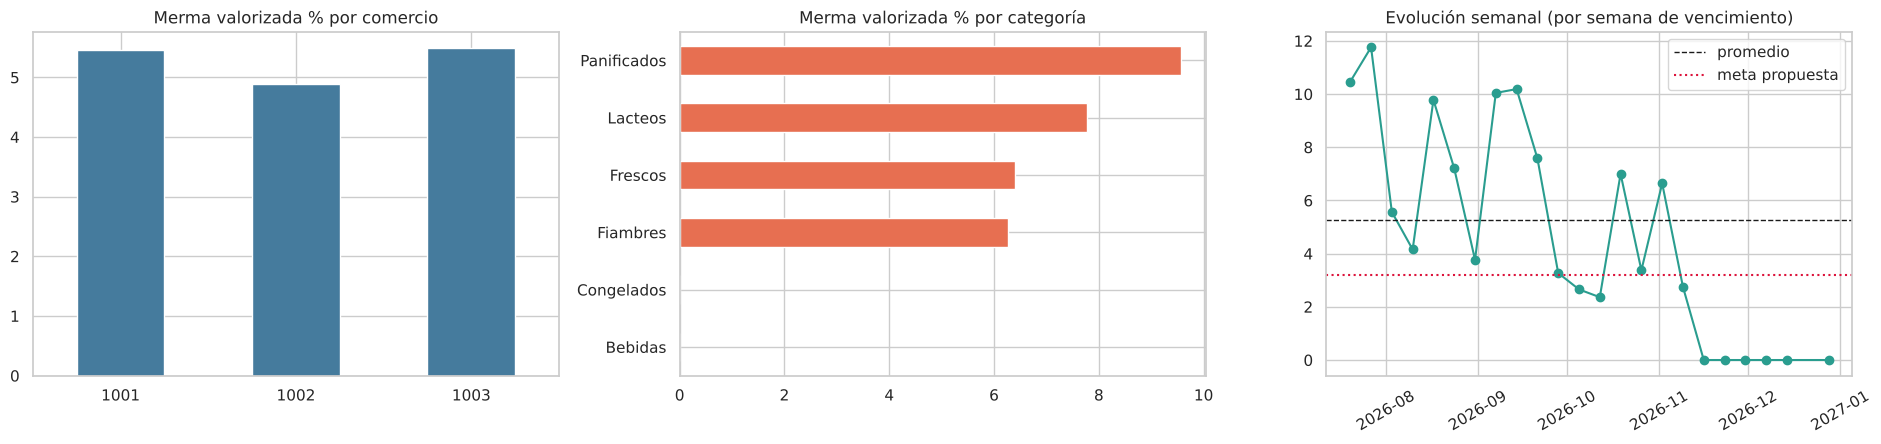

In [9]:
def merma_por(df, col):
    return df.groupby(col).apply(lambda g: 100 * (g.merma * g.costo).sum() / (g.cantidad_inicial * g.costo).sum())

cerrados["semana"] = cerrados.fecha_vencimiento.dt.to_period("W").dt.start_time
fig, ax = plt.subplots(1, 3, figsize=(19, 4.6))
merma_por(cerrados, "telegram_id").plot.bar(ax=ax[0], rot=0, color="#457b9d"); ax[0].set_title("Merma valorizada % por comercio"); ax[0].set_xlabel("")
merma_por(cerrados, "categoria").sort_values().plot.barh(ax=ax[1], color="#e76f51"); ax[1].set_title("Merma valorizada % por categoría"); ax[1].set_ylabel("")
sem = merma_por(cerrados, "semana")
ax[2].plot(sem.index, sem.values, "o-", color="#2a9d8f"); ax[2].axhline(base_merma, color="k", ls="--", lw=1, label="promedio"); ax[2].axhline(META["Merma valorizada %"][0], color="crimson", ls=":", label="meta propuesta")
ax[2].set_title("Evolución semanal (por semana de vencimiento)"); ax[2].tick_params(axis="x", rotation=30); ax[2].legend()
plt.tight_layout(); plt.show()

### 4.4 Tarjetas de KPIs (vista para el dashboard)

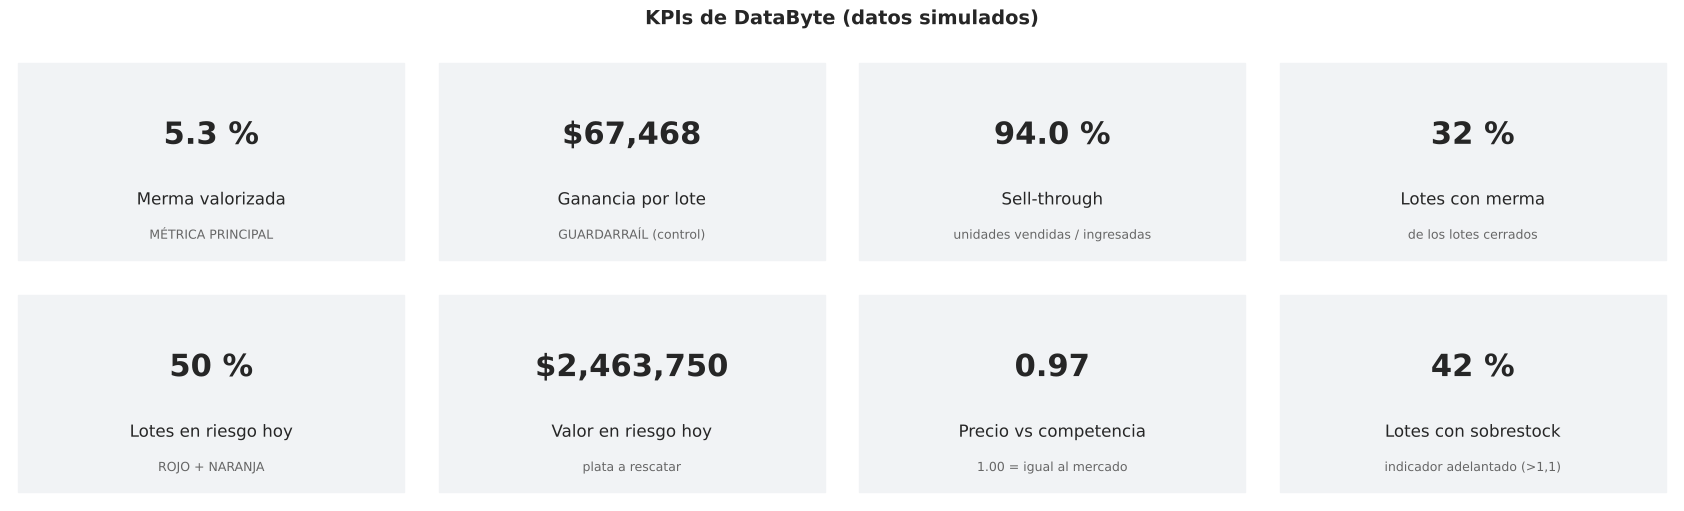

In [10]:
tarjetas = [("Merma valorizada", f"{kpi['Merma valorizada %']:.1f} %", "MÉTRICA PRINCIPAL"),
            ("Ganancia por lote", f"${kpi['Ganancia bruta por lote ($)']:,.0f}", "GUARDARRAÍL (control)"),
            ("Sell-through", f"{kpi['Sell-through %']:.1f} %", "unidades vendidas / ingresadas"),
            ("Lotes con merma", f"{kpi['% de lotes con merma']:.0f} %", "de los lotes cerrados"),
            ("Lotes en riesgo hoy", f"{kpi['Lotes en riesgo hoy %']:.0f} %", "ROJO + NARANJA"),
            ("Valor en riesgo hoy", f"${kpi['Valor en riesgo hoy ($)']:,.0f}", "plata a rescatar"),
            ("Precio vs competencia", f"{kpi['Índice de precio vs competencia']:.2f}", "1.00 = igual al mercado"),
            ("Lotes con sobrestock", f"{100*(c.sobrestock > 1.1).mean():.0f} %", "indicador adelantado (>1,1)")]
fig, axs = plt.subplots(2, 4, figsize=(17, 5.2))
for a, (t, v, sub) in zip(axs.ravel(), tarjetas):
    a.axis("off"); a.add_patch(plt.Rectangle((0.02, 0.04), 0.96, 0.92, fill=True, color="#f1f3f5", transform=a.transAxes))
    a.text(.5, .62, v, ha="center", va="center", fontsize=22, fontweight="bold", transform=a.transAxes)
    a.text(.5, .30, t, ha="center", fontsize=12, transform=a.transAxes); a.text(.5, .14, sub, ha="center", fontsize=9, color="#666", transform=a.transAxes)
fig.suptitle("KPIs de DataByte (datos simulados)", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.savefig("kpis_tarjetas.png", dpi=130); plt.show()

## 5. Conexión con el ROI y con el modelo (coherencia del proyecto)
La métrica principal es **la misma** que usamos para medir el efecto del bot en el notebook 03. Así el pitch cuenta una sola historia: *"medimos la merma valorizada, el Score busca bajarla sin sacrificar la ganancia por lote"*.

In [11]:
roi = pd.read_csv("data/roi_escenarios.csv", index_col=0)
print("Objetivo de merma según el ROI simulado (unidades, no valorizada):")
display(roi[["adherencia", "merma sin bot %", "merma con bot %", "ganancia extra/lote $"]].round(1))
print(f"\nMeta propuesta de merma valorizada: {META['Merma valorizada %'][0]} %  (línea base actual: {base_merma:.1f} %)")

Objetivo de merma según el ROI simulado (unidades, no valorizada):


,adherencia,merma sin bot %,merma con bot %,ganancia extra/lote $
escenario,,,,
Conservador,0.3,7.9,5.5,-855.3
Base,0.6,6.3,2.6,783.5
Optimista,0.9,4.8,0.6,2553.9



Meta propuesta de merma valorizada: 3.2 %  (línea base actual: 5.3 %)


## 6. Conclusiones (texto para el informe / pitch)
1. **Métrica elegida: *merma valorizada (% del costo ingresado)*, con intervalo de confianza**, acompañada de **ganancia bruta por lote** como guardarraíl.
2. **Justificación por distribuciones**: la merma por lote está **inflada de ceros y con cola larga** (la mayoría de los lotes no tiene merma y unos pocos tienen mucha) → la media simple de porcentajes y la mediana no sirven; stock y vencimiento tienen **colas largas y escalas distintas** → hay que **ponderar** y usar **porcentajes**; las ventas son **asimétricas y sobredispersas** → para el pronóstico usamos **MAE/WAPE** y no MAPE.
3. **Indicador adelantado**: el **ratio de sobrestock** (ingresado ÷ ventas esperadas) separa los lotes con merma de los que no; permite avisar **antes** de que el producto venza.
4. **KPIs**: 8 indicadores con fórmula, fuente y meta; la función `calcular_kpis` los calcula con las tablas reales del Sheet.
5. **Limitaciones**: valores de ejemplo (datos simulados); metas propuestas a validar; falta el **costo del lote** en `Lotes_Registrados` para valorizar con datos reales (la factura lo trae: conviene guardarlo).

**Para usar datos reales:** pasar a `calcular_kpis` los lotes ya vencidos de `Lotes_Registrados` (con `cantidad_inicial`, `costo` y `merma` = cantidad restante al vencer) y las ventas de `Ventas_Registradas`.